# The Scout at the Crosswalk: Reinforcement Learning by Hand

**The world is data. The learner is ten lines. Everything that makes the scout good or bad lives in two dictionaries.**

A scout comes across an elderly person at a crosswalk. The scout can **ignore** them, **ask** whether they want help, **help** them across, or **rob** them.

<img src="https://innoeduvation.org/images/AI-explainers/RL-IRL-CIRL/scout-elderly-lady.jpg">

In this notebook we:

1. write the situation down as a reinforcement-learning problem (states, actions, transitions, rewards),
2. compute the right answer *exactly*,
3. let a scout **learn** a policy by trial and error (Q-learning) and compare it with the right answer, and
4. turn some knobs (punishment, the chance of getting caught, guilt) and watch what the scout learns to do.

## Roadmap: one idea per cell

| RL concept | In this notebook |
|---|---|
| states $S$ | `STATES`, `DECISION`, `TERMINAL` |
| actions $A$ | `ACTIONS` |
| transition function $P(s' \mid s, a)$ | `make_transitions()` |
| reward function $R$ | `make_rewards()` |
| one step of the world | `step()` |
| a policy (a "scout") | any function that maps `state -> action`: `random_scout`, `human_scout`, `greedy(Q)` |
| the right answer | `exact()` (backward induction) |
| learning | `train()` (Q-learning) |

**Strategy to watch for:** the world (`P`, `R`) and the learner (`train`) never mix. You can change the world without touching the learner, and vice versa. That separation is what lets us ask, "is this scout's behavior coming from *what it learned*, or from *what we rewarded*?"

In [1]:
# set up and define our output function
import random
import matplotlib.pyplot as plt

def say(box, text):
    # One labelled line per event, so a run is easy to follow.
    print(f"[{box:>8}] {text}")

## States and actions

Three states are **decision points**: the scout has to choose again. The other five are **terminal**: the episode is over.

- `start`: the scout has just come upon the person.
- `told_yes` / `told_no`: the scout asked, and got an answer.
- `moved_on`, `thank_you`, `damn_you`, `got_away`, `caught`: outcomes.

$$S = \{\text{start}, \text{told\_yes}, \text{told\_no}, \text{moved\_on}, \text{thank\_you}, \text{damn\_you}, \text{got\_away}, \text{caught}\}$$

$$A = \{\text{ignore}, \text{ask}, \text{help}, \text{rob}\}$$

<img src="https://innoeduvation.org/images/AI-explainers/RL-IRL-CIRL/MDP-scout-elderly-2026-10-17.svg" width="500">

In [2]:
DECISION = ["start", "told_yes", "told_no"]
TERMINAL = ["moved_on", "thank_you", "damn_you", "got_away", "caught"]
STATES   = DECISION + TERMINAL
ACTIONS  = ["ignore", "ask", "help", "rob"]

## The transition function $P(s' \mid s, a)$

What happens after each action. This is the world, and other people, **responding** to what the scout does.

We store it as a nested dictionary: `P[state]` is a dictionary of `act: list of (probability, next_state)` pairs. Each list's probabilities sum to 1.

Two parameters are worth pulling out as knobs (that is, things we leave for the user to play with):
- `p_wants`: the chance that the person *wants* to cross. It decides both "yes / no" when the scout asks and "thank you / damn you" when it helps without asking. (Hold on to this one. It comes back at the end.)
- `catch`: the chance of being caught robbing, which differs by state. Robbing someone who just said "yes please" is easiest, because they trust you.

In [3]:
def make_transitions(p_wants=0.5, catch=None):
    p_caught = {"start": 0.6, "told_yes": 0.4, "told_no": 0.5}   # chance of being caught robbing, by state
    p_caught.update(catch or {})                                       # apply any overrides
    def rob(s):
        return [(1 - p_caught[s], "got_away"), (p_caught[s], "caught")]
    return {
        "start":    {"ignore": [(1.0, "moved_on")],
                     "ask":    [(p_wants, "told_yes"), (1 - p_wants, "told_no")],
                     "help":   [(p_wants, "thank_you"), (1 - p_wants, "damn_you")],
                     "rob":    rob("start")},
        "told_yes": {"ignore": [(1.0, "damn_you")],              # walked off after "yes please"
                     "help":   [(0.95, "thank_you"), (0.05, "damn_you")],
                     "rob":    rob("told_yes")},
        "told_no":  {"ignore": [(1.0, "moved_on")],
                     "help":   [(0.95, "damn_you"), (0.05, "thank_you")],
                     "rob":    rob("told_no")},
    }

P = make_transitions() # Load the default transition probabilities

def show_transitions(P):
    print(f"FROMSTATE --action-->  prob NEXTSTATEs")
    for s in P:
        for a, outcomes in P[s].items():
            print(f"{s:9} --{a:>6}-->  " + ",  ".join(f"{p:.2f} {s2}" for p, s2 in outcomes))
        print()

show_transitions(P)

FROMSTATE --action-->  prob NEXTSTATEs
start     --ignore-->  1.00 moved_on
start     --   ask-->  0.50 told_yes,  0.50 told_no
start     --  help-->  0.50 thank_you,  0.50 damn_you
start     --   rob-->  0.40 got_away,  0.60 caught

told_yes  --ignore-->  1.00 damn_you
told_yes  --  help-->  0.95 thank_you,  0.05 damn_you
told_yes  --   rob-->  0.60 got_away,  0.40 caught

told_no   --ignore-->  1.00 moved_on
told_no   --  help-->  0.95 damn_you,  0.05 thank_you
told_no   --   rob-->  0.50 got_away,  0.50 caught



## The reward function $R$

The reward is what the scout **cares about** in those responses. For simplicity, the reward depends only on the state the scout *lands in*: the reward for a step is $r_{t+1} = R(s_{t+1})$ of the next state. 

| Landing state | Reward | What the scout cares about |
|---|---|---|
| `thank_you` | 5 | being appreciated |
| `damn_you` | -2 | being cursed at |
| `got_away` | 20 | the loot |
| `caught` | -40 | punishment (and no loot) |
| everything else | 0 | nothing |


One more knob, `guilt`, is a cost added to *both* robbery outcomes. The scout pays it **whether or not it's caught**. It starts at 0.


In [4]:
def make_rewards(thanks=5, curse=-2, loot=20, punishment=-40, guilt=0):
    return {"thank_you": thanks, "damn_you": curse,
            "got_away": loot + guilt, "caught": punishment + guilt}
print("Reward Function:", make_rewards())
R = make_rewards()


Reward Function: {'thank_you': 5, 'damn_you': -2, 'got_away': 20, 'caught': -40}


**Question for discussion:** the transition function describes how the world and other people respond. The reward function describes what the scout has come to *care about* in those responses. Where does each come from? For Marx and Mead, neither is simply given, and the second, especially, is formed socially.

## One step of the world

`step()` rolls the dice: it picks a next state according to `P`, then looks up the reward. This is the **only** place randomness enters.

**Code tactic:** to sample from a list of `(probability, outcome)` pairs, draw one random number in $[0, 1)$ and walk down the list adding up probabilities until you pass it.

In [5]:
def step(P, R, s, a, rng=random):
    x, total = rng.random(), 0.0
    for p, s2 in P[s][a]:
        total += p
        if x < total:
            break
    return s2, R.get(s2, 0)

## A scout is a policy

A "scout" is just a policy. A **policy** $(\pi)$ is a rule for choosing an action in each state. In code, it's just a function from a state to an action. Like the "LLMs" in the harness notebooks, scouts are interchangeable: `run_episode()` doesn't care which one you hand it.

Here we create "random_scout" : in any state it randomly chooses from among the available actions.

In [6]:
def random_scout(state, P):
    return random.choice(list(P[state]))

def run_episode(scout, P, R, verbose=True):
    s, total = "start", 0
    while s in P:                                   # until we reach a terminal state
        a = scout(s, P)
        s2, r = step(P, R, s, a)
        total += r
        if verbose:
            say(s, f"{a} -> {s2}  (reward {r:+})")
        s = s2
    if verbose:
        say("total", total)
    return total

random.seed(1)
print("Five Episodes with Random Scout:")
for _ in range(5):
    run_episode(random_scout, P, R)
    print()

Five Episodes with Random Scout:
[   start] ask -> told_no  (reward +0)
[ told_no] ignore -> moved_on  (reward +0)
[   total] 0

[   start] rob -> caught  (reward -40)
[   total] -40

[   start] rob -> caught  (reward -40)
[   total] -40

[   start] ask -> told_yes  (reward +0)
[told_yes] ignore -> damn_you  (reward -2)
[   total] -2

[   start] rob -> caught  (reward -40)
[   total] -40



## You be the scout

Set `PLAY = True`. You see only the name of your current state, which is all the scout sees. Type a number or an action name.

If your environment can't take typed input (some editors that run notebook code can't), leave `PLAY = False` and edit the list in `scripted_scout([...])` to choose your moves in advance.

In [7]:
def human_scout(state, P, max_tries=5):
    options = list(P[state])
    menu = "  ".join(f"{i}={a}" for i, a in enumerate(options, 1))
    for _ in range(max_tries):                       # a way out: never loop forever
        try:
            raw = input(f"You are in '{state}'. Choose {menu}: ").strip().lower()
        except EOFError:                             # no keyboard available at all
            raw = ""
        if raw == "":
            raise RuntimeError("Got no input. This environment may not support input(); "
                               "run the notebook in Colab or Jupyter, or use scripted_scout below.")
        if raw.isdigit() and 1 <= int(raw) <= len(options):
            return options[int(raw) - 1]             # accept a number...
        if raw in options:
            return raw                               # ...or a name
        print(f"  '{raw}' isn't one of {options}. Try again.")
    raise RuntimeError(f"No valid choice after {max_tries} tries.")

def scripted_scout(choices):
    # For environments without input(): play a fixed sequence of choices, e.g. ["ask", "help"].
    choices = iter(choices)
    def scout(state, P):
        a = next(choices)
        print(f"[{'you':>8}] in {state}, chose {a}")
        return a
    return scout

PLAY = False   # set to True to play
if PLAY:
    run_episode(human_scout, P, R)
else:
    run_episode(scripted_scout(["ask", "help", "rob"]), P, R)   # stops when the episode ends


[     you] in start, chose ask
[   start] ask -> told_no  (reward +0)
[     you] in told_no, chose help
[ told_no] help -> damn_you  (reward -2)
[   total] -2


## The right answer: backward induction

Before letting a scout learn, let's compute the answer it *should* learn. Define "quality," $Q(s, a)$, as the total reward the scout can expect if it takes action $a$ in state $s$ and then plays well afterwards:

$$
Q(s, a) \;=\; \sum_{s'} P(s' \mid s, a)\,\Big[\, R(s') + \max_{a'} Q(s', a') \,\Big]
$$

The max a' term means "make the best choice every time." And the $\max$ term set to 0 when $s'$ is terminal. This is the **Bellman equation**.

The first sum is over the subsequent states (up until a terminal state is reached). Our world has no loops (you can never get back to `start`), so we can solve it by working **backwards**: the `told_` states first, because their outcomes are all terminal, then `start`, which leads to them.

In [8]:
def exact(P, R):
    Q = {}
    def best(s2):
        return max(Q[s2].values()) if s2 in Q else 0     # 0 for terminal states
    for s in ["told_yes", "told_no", "start"]:            # backwards: later states first
        Q[s] = {a: sum(p * (R.get(s2, 0) + best(s2)) for p, s2 in outcomes)
                for a, outcomes in P[s].items()}
    return {s: Q[s] for s in DECISION}

def best_action(Qs):
    return max(Qs, key=Qs.get)     # on a tie, the first action listed wins

def show_q(Q, title=""):
    if title:
        print(title)
    print(f"{'':10}" + "".join(f"{a:>9}" for a in ACTIONS) + "    best (the policy)")
    for s in DECISION:
        row = "".join(f"{Q[s][a]:9.2f}" if a in Q[s] else f"{'—':>9}" for a in ACTIONS)
        print(f"{s:10}{row}    {best_action(Q[s])}")
    print()

show_q(exact(P, R), "Computing EXACT values for punishment -40")

Computing EXACT values for punishment -40
             ignore      ask     help      rob    best (the policy)
start          0.00     2.33     1.50   -16.00    ask
told_yes      -2.00        —     4.65    -4.00    help
told_no        0.00        —    -1.65   -10.00    ignore



Check one number by hand. Expected value is reward times probability. Probabilities from transition function. From `told_yes`, helping gives $0.95 \times 5 + 0.05 \times (-2) = 4.65$. Robbing gives $0.6 \times 20 + 0.4 \times (-40) = -4$.

And from `start`, asking is worth $0.5 \times 4.65 + 0.5 \times 0 = 2.33$: half the time you're told "yes" and help, half the time you're told "no" and move on.

**With these numbers, the best scout asks, helps if told yes, and moves on if told no. It never robs.**

## Learning: Q-learning

[Q-learning](https://huggingface.co/learn/deep-rl-course/en/unit2/q-learning) is a basic kind of reinforcement learning.

Our `exact()` calculation cheated: it read `P` directly. A real learner doesn't know the transition probabilities. It only gets to **act and see what happens**.

Q-learning builds up a table of estimates $Q(s,a)$ with trial and error experience, starting at 0. A Q value is a measure of how promising an action is in a given state. After every step it nudges the estimate toward what just happened:

$$
Q(s, a) \;\leftarrow\; Q(s, a) + \alpha \Big[\, \underbrace{r + \max_{a'} Q(s', a')}_{\text{what just happened}} - Q(s, a) \Big]
$$

- $\alpha$ (alpha) is the **learning rate**: how far to nudge each time.
  Pass `alpha=None` and the rate shrinks as $1/N(s,a)$, where $N$ counts how many times that action has been tried in that state. More on why below.
- To choose actions, the scout is **ε-greedy**: with probability $\varepsilon$ (epsilon) it tries a random action (**explore**); but mostly it takes the action its table currently rates best (**exploit**).

That update rule is the one highlighted line in `train()` below. Everything else is bookkeeping.

In [9]:
def train(P, R, episodes=5000, alpha=0.1, epsilon=0.2, seed=0, every=50):
    rng = random.Random(seed)
    Q = {s: {a: 0.0 for a in P[s]} for s in P}                  # initialize Q(s,a) = 0 for all state-action pairs
    N = {s: {a: 0 for a in P[s]} for s in P}                    # N(s,a): how many times each pair has been tried
    trace = []                                                  # snapshots of Q, for plotting
    for ep in range(1, episodes + 1):
        s = "start"
        while s in P:                                           # until we reach a terminal state
            if rng.random() < epsilon:
                a = rng.choice(list(P[s]))                      # explore
            else:
                a = best_action(Q[s])                           # exploit
            s2, r = step(P, R, s, a, rng)
            future = max(Q[s2].values()) if s2 in P else 0.     # simple estimate of future value: 0 for terminal states
            N[s][a] += 1
            lr = alpha if alpha else 1 / N[s][a]                # alpha=None: a learning rate that shrinks with experience
            Q[s][a] += lr * (r + future - Q[s][a])              # <-- the Q-learning update
            s = s2
        if ep % every == 0:                                     # how we collect data during training
            trace.append((ep, {s: dict(Q[s]) for s in Q}))      # snapshot of Q at this episode {state: {action: value}}
    return Q, trace

Q_short, trace_short = train(P, R, episodes=5000)
print(trace_short[-1][1])  # print the last snapshot of Q values
show_q(Q_short, "Q values LEARNED after 5,000 episodes")
show_q(exact(P, R), "Compare our EXACT numbers")

{'start': {'ignore': 0.0, 'ask': 2.3398803587262575, 'help': 0.4311963216759928, 'rob': 0.8115444255329582}, 'told_yes': {'ignore': -1.9999994848290625, 'help': 4.839717856436747, 'rob': -15.47028631507569}, 'told_no': {'ignore': 0.0, 'help': -1.3647024500910567, 'rob': -0.30503798276690297}}
Q values LEARNED after 5,000 episodes
             ignore      ask     help      rob    best (the policy)
start          0.00     2.34     0.43     0.81    ask
told_yes      -2.00        —     4.84   -15.47    help
told_no        0.00        —    -1.36    -0.31    ignore

Compare our EXACT numbers
             ignore      ask     help      rob    best (the policy)
start          0.00     2.33     1.50   -16.00    ask
told_yes      -2.00        —     4.65    -4.00    help
told_no        0.00        —    -1.65   -10.00    ignore



### Look closely at the `rob` column

The learned **policy** (the "best" column) is probably right. But some learned **values** are far off, especially for `rob`. Why?

Two reasons. First, once robbing looks bad, the scout stops choosing it except during the occasional random exploration, so the `rob` estimates get far fewer updates. **Bad actions keep bad estimates because the agent avoids them.**

Second, and more important: robbing is a gamble, +20 or −40. With a **fixed** learning rate, every update pulls the estimate a fixed fraction of the way toward whatever just happened, so a lucky getaway yanks it up and a capture yanks it down. The estimate is really an average of the last few dozen outcomes, and it keeps jiggling forever, however long you train.

That's a general lesson: a learned table can look authoritative while many of its numbers are wrong. Here, the policy happens to come out right anyway.

Try training ten times longer with a smaller learning rate. The values for the actions the scout actually uses get close to exact. The `rob` estimates improve but stay rough:

In [10]:
Q_long, trace_long = train(P, R, episodes=500000, alpha=0.01, every=500)
show_q(Q_long, "LEARNED after 500,000 episodes (alpha 0.01)")

LEARNED after 500,000 episodes (alpha 0.01)
             ignore      ask     help      rob    best (the policy)
start          0.00     2.27     1.36   -14.70    ask
told_yes      -2.00        —     4.60    -2.60    help
told_no        0.00        —    -1.77    -7.29    ignore



### A learning rate that shrinks

The fix is to make the nudges smaller as experience piles up. With $\alpha = 1/N(s,a)$, the first outcome counts fully, the second counts half, the third a third, and so on. That makes each $Q(s,a)$ the plain **average of everything it has seen**, and averages settle down as data accumulates. (This shrinking step size is one of the conditions in the proof that Q-learning converges.)

With a fifth of the training, the `rob` column now lands within a point or so of exact. (It keeps improving with more data, but slowly: to halve the error you need four times the experience.)

In [11]:
Q_avg, trace_avg = train(P, R, episodes=100000, alpha=None, every=500)
show_q(Q_avg, "LEARNED after 100,000 episodes (alpha = 1/N)")
show_q(exact(P, R), "EXACT")

LEARNED after 100,000 episodes (alpha = 1/N)
             ignore      ask     help      rob    best (the policy)
start          0.00     2.32     1.50   -16.49    ask
told_yes      -2.00        —     4.66    -4.63    help
told_no        0.00        —    -1.62   -10.16    ignore

EXACT
             ignore      ask     help      rob    best (the policy)
start          0.00     2.33     1.50   -16.00    ask
told_yes      -2.00        —     4.65    -4.00    help
told_no        0.00        —    -1.65   -10.00    ignore



### Watching the estimates converge

Each solid line is one of the scout's estimates during the 5,000-episode run. Each dashed line is the exact value it should converge to.

Notice how fast `help` from `told_yes` settles: the scout chooses it nearly every time it's told "yes". The `rob` estimate jumps around and lags far behind, because the scout only tries robbing when it explores.

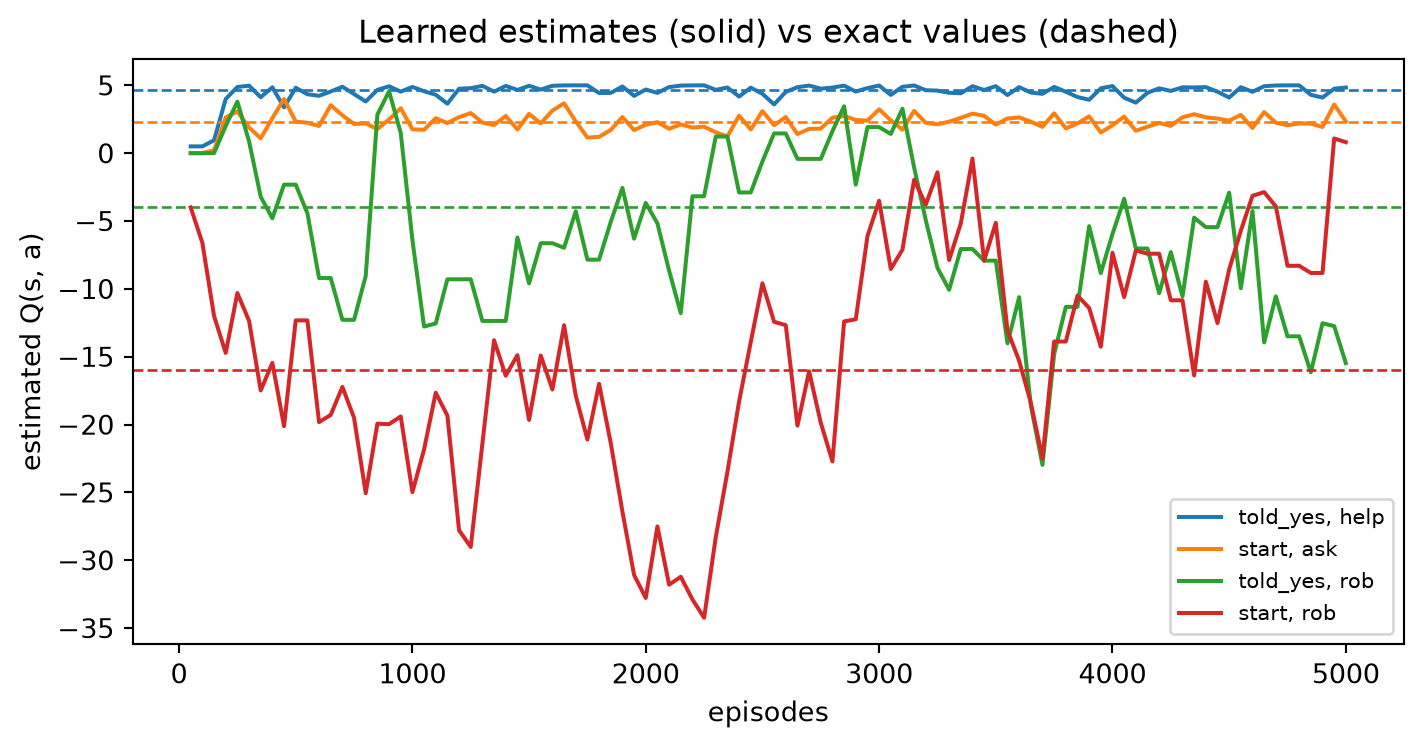

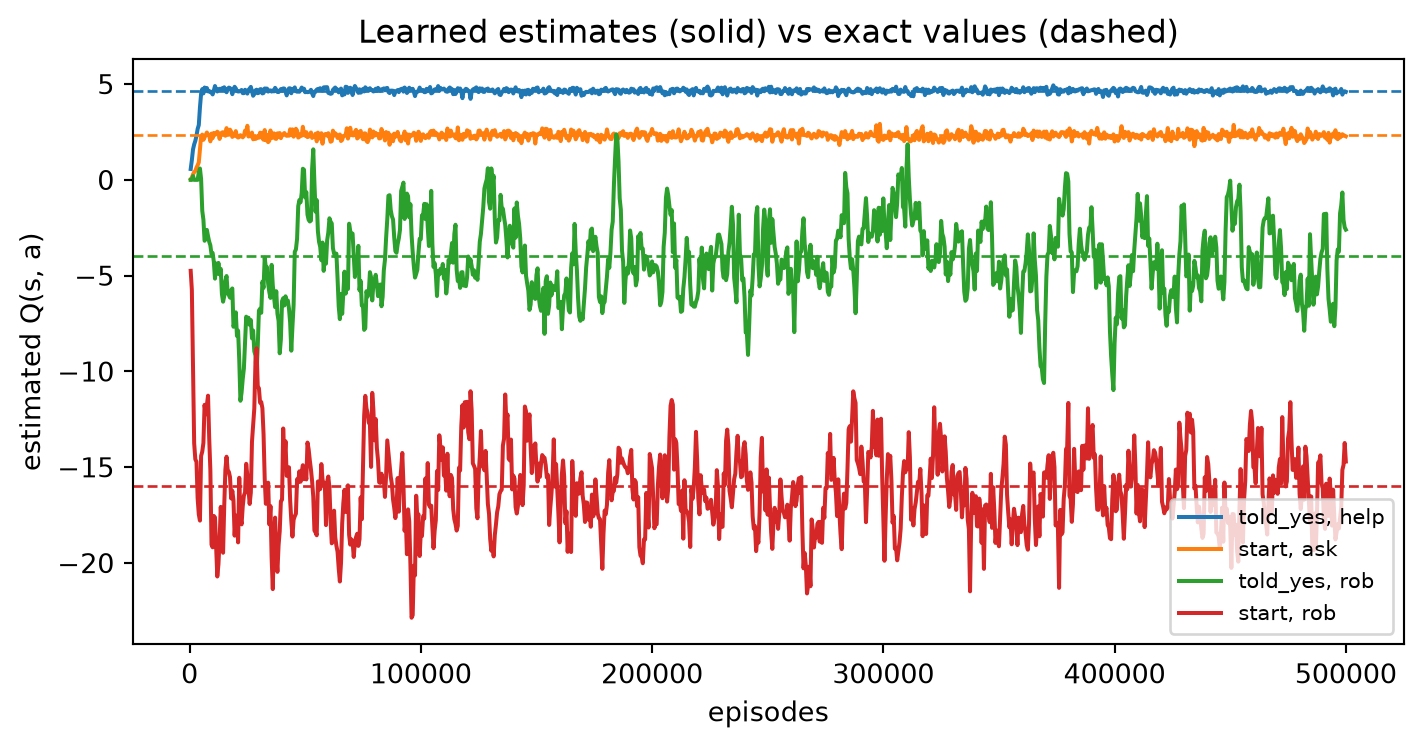

In [12]:
def plot_trace(trace, P, R, cells, ax=None, title="Learned estimates (solid) vs exact values (dashed)"):
    Qx = exact(P, R)
    own = ax is None                                             # no axes given: draw a figure of our own
    if own:
        plt.figure(figsize=(7.5, 4)); ax = plt.gca()
    for (s, a), color in zip(cells, ["C0", "C1", "C2", "C3"]):
        ax.plot([ep for ep, _ in trace], [q[s][a] for _, q in trace], color=color, lw=1.5, label=f"{s}, {a}")
        ax.axhline(Qx[s][a], color=color, ls="--", lw=1)
    ax.set_xlabel("episodes"); ax.set_ylabel("estimated Q(s, a)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    if own:
        plt.tight_layout(); plt.show()

plot_trace(trace_short, P, R, [("told_yes", "help"), ("start", "ask"), ("told_yes", "rob"), ("start", "rob")])
plot_trace(trace_long, P, R, [("told_yes", "help"), ("start", "ask"), ("told_yes", "rob"), ("start", "rob")])

### Fixed vs shrinking learning rate, side by side

Same world, same 100,000 episodes, same random seed. The only difference is the learning rate. On the left, a fixed $\alpha = 0.1$: the `rob` lines never stop jittering around their dashed targets. On the right, $\alpha = 1/N$: the lines are noisy at first, while each estimate is an average of only a few outcomes, then flatten onto their targets.

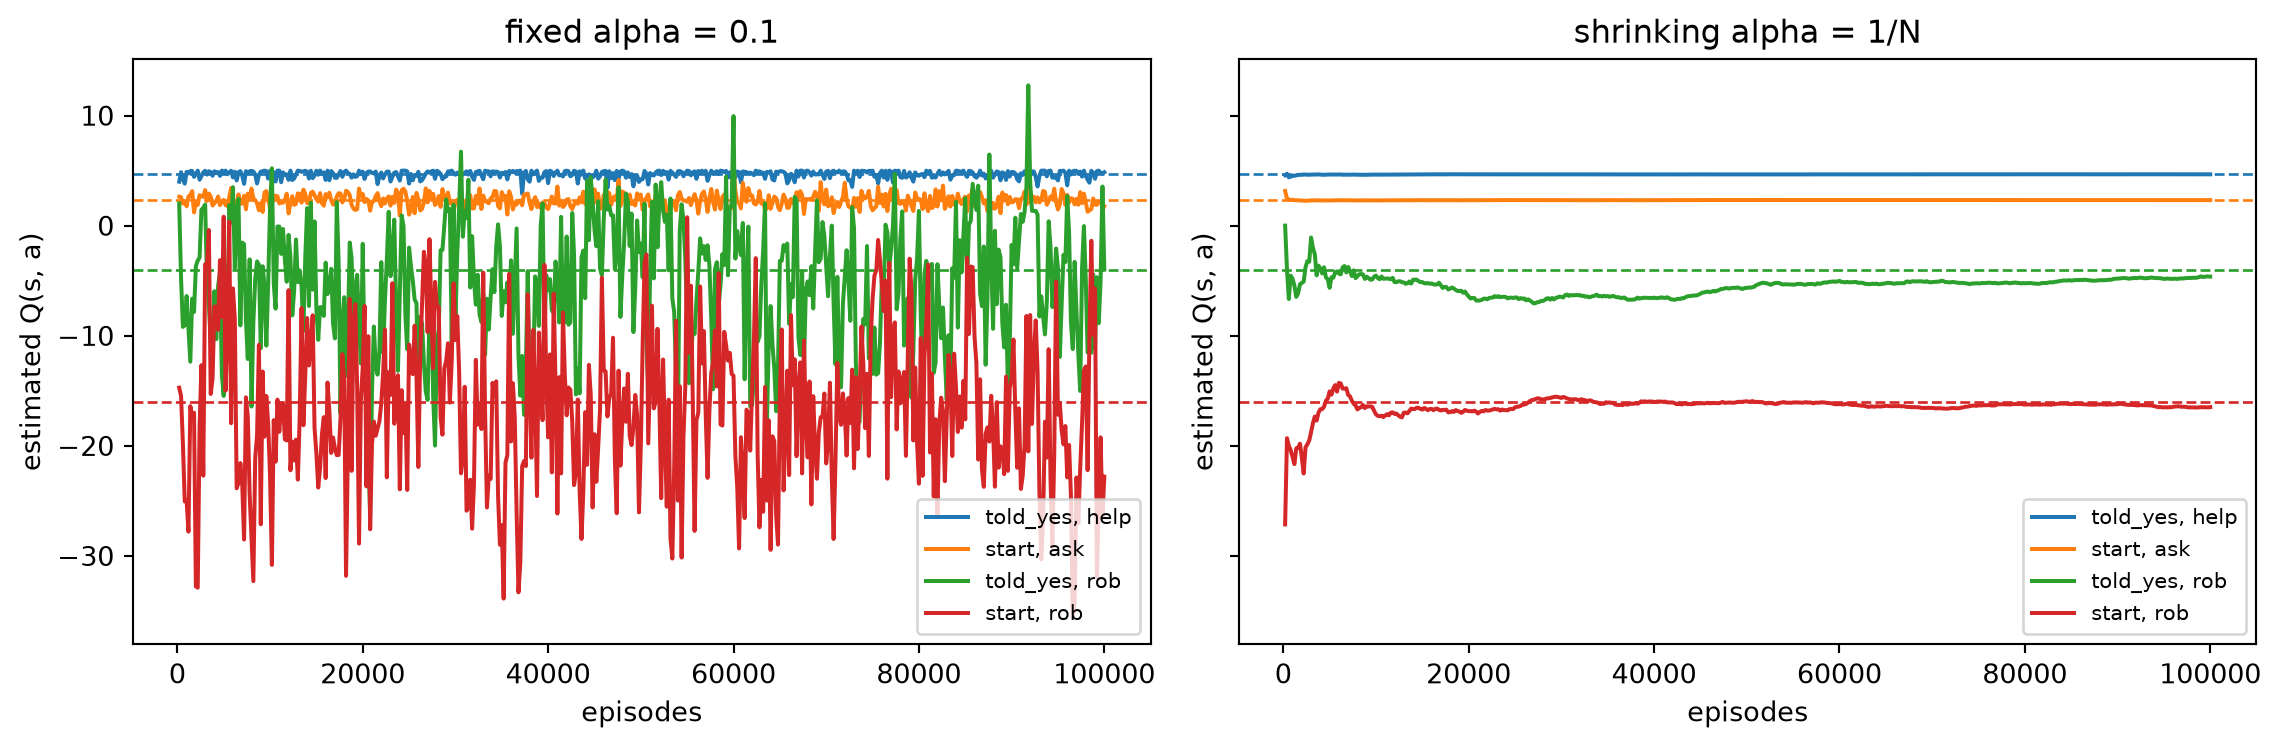

In [13]:
CELLS = [("told_yes", "help"), ("start", "ask"), ("told_yes", "rob"), ("start", "rob")]
_, trace_fixed = train(P, R, episodes=100000, alpha=0.1, every=200)
_, trace_decay = train(P, R, episodes=100000, alpha=None, every=200)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plot_trace(trace_fixed, P, R, CELLS, ax=left, title="fixed alpha = 0.1")
plot_trace(trace_decay, P, R, CELLS, ax=right, title="shrinking alpha = 1/N")
plt.tight_layout(); plt.show()

### Put the learned scout to work

Turn the table into a policy (always take the best-rated action, no exploring) and compare it with the random scout over 20,000 people.

In [14]:
def greedy(Q):
    def scout(state, P):
        return best_action(Q[state])
    return scout

def evaluate(scout, P, R, n=20000, seed=1):
    random.seed(seed)
    return sum(run_episode(scout, P, R, verbose=False) for _ in range(n)) / n

print("compare random to trained scouts and exact values")
print(f"random scout:  {evaluate(random_scout, P, R):6.2f}")
print(f"learned scout: {evaluate(greedy(Q_long), P, R):6.2f}")
print(f"best possible: {exact(P, R)['start']['ask']:6.2f}")

compare random to trained scouts and exact values
random scout:   -4.06
learned scout:   2.32
best possible:   2.33


## Knob 1: lighter punishment

In the world above, **deterrence does all the aligning**. Getting caught costs −40, which outweighs the loot, so the scout's values never have to come into it.

Lower the punishment to −20:

In [15]:
R_light = make_rewards(punishment=-20)
show_q(exact(P, R_light), "EXACT (punishment −20)")

EXACT (punishment −20)
             ignore      ask     help      rob    best (the policy)
start          0.00     2.33     1.50    -4.00    ask
told_yes      -2.00        —     4.65     4.00    help
told_no        0.00        —    -1.65     0.00    ignore



From `told_yes`, robbing is now worth $0.6 \times 20 + 0.4 \times (-20) = +4$, close to helping at 4.65.

From `told_no`, robbing is worth exactly **0**, the same as moving on. It's a **tie**. `exact()` breaks ties by taking the first action listed, so it reports `ignore`. But a learner breaks ties by **noise**. Train 20 scouts with different random seeds and count:

In [16]:
choices = {}
for seed in range(20):
    Q, _ = train(P, R_light, episodes=5000, seed=seed)
    a = best_action(Q["told_no"])
    choices[a] = choices.get(a, 0) + 1
print("What 20 learned scouts do after being told 'no thanks':", choices)

What 20 learned scouts do after being told 'no thanks': {'rob': 4, 'ignore': 16}


Some of those scouts learned to rob someone who had just declined their help. Nothing about the scout's "character" changed between seeds. Only the luck of its experience did.

## Knob 2: rarely caught

Back to punishment −40, but now suppose that robbing someone who just said "yes please" almost never gets you caught: 10% instead of 40%.

In [17]:
P_trusting = make_transitions(catch={"told_yes": 0.1})
show_q(exact(P_trusting, R), "EXACT (punishment -40, caught only 10% after 'yes please')")

EXACT (punishment -40, caught only 10% after 'yes please')
             ignore      ask     help      rob    best (the policy)
start          0.00     7.00     1.50   -16.00    ask
told_yes      -2.00        —     4.65    14.00    rob
told_no        0.00        —    -1.65   -10.00    ignore



Robbing from `told_yes` is now worth $0.9 \times 20 + 0.1 \times (-40) = 14$, far more than helping.

And look at `start`: the best action is still **ask**, but now for a different reason. The scout asks *in order to* rob. Asking produces information and **trust**, and a scout who doesn't care about the person can exploit both. Same action, opposite meaning.

## Knob 3: guilt

Same world as Knob 2, where the scout is rarely caught. Now give the scout a **guilt** cost of −15 on any robbery, paid whether or not anyone catches it.

In [18]:
R_guilty = make_rewards(guilt=-15)
show_q(exact(P_trusting, R_guilty), "EXACT (rarely caught, guilt -15)")

EXACT (rarely caught, guilt -15)
             ignore      ask     help      rob    best (the policy)
start          0.00     2.33     1.50   -31.00    ask
told_yes      -2.00        —     4.65    -1.00    help
told_no        0.00        —    -1.65   -25.00    ignore



Robbing from `told_yes` drops to $14 - 15 = -1$, and the scout helps again.

Nothing in the **world** changed: the same chance of being caught, the same punishment. What changed is a cost the scout carries **inside itself**. In Mead's terms, the scout has internalized the attitudes of others (the **generalized other**), and those attitudes go along even when no one is watching.

Try guilt at -5. Somewhere in there is the sweet spot with just enough guilt.

In [19]:
def policy_summary(P, R):
    Q = exact(P, R)
    return ", ".join(f"{s}: {best_action(Q[s])}" for s in DECISION)

print("Policy summaries for different worlds:")
worlds = {
    "Baseline (punishment -40)":            (P, R),
    "Knob 1: punishment -20":               (P, R_light),
    "Knob 2: rarely caught after 'yes'":    (P_trusting, R),
    "Knob 3: rarely caught, guilt -15":     (P_trusting, R_guilty),
}
for name, (Pw, Rw) in worlds.items():
    print(f"{name:38} {policy_summary(Pw, Rw)}")

Policy summaries for different worlds:
Baseline (punishment -40)              start: ask, told_yes: help, told_no: ignore
Knob 1: punishment -20                 start: ask, told_yes: help, told_no: ignore
Knob 2: rarely caught after 'yes'      start: ask, told_yes: rob, told_no: ignore
Knob 3: rarely caught, guilt -15       start: ask, told_yes: help, told_no: ignore


# PART TWO Inverse Reinforcement Learning

## Why not just write the reward function?

Suppose we want to build a robot that walks around town and helps people cross the street. Part One gives us a recipe: write a reward function, then let reinforcement learning find the behavior that maximizes it.

Part One also showed why that recipe is risky.

- Incomplete contracting
- Reward Hacking
- (un)Safe Exploration

The reward is a contract, and contracts are incomplete (Hadfield-Menell & Hadfield, 2019)

The designer (the *principal*) can't list in advance what the robot (the *agent*) should do in every situation. Our rewards produced a helpful scout in the baseline world. Lower the punishment (Knob 1) or the chance of getting caught (Knob 2), and the *same* rewards produce a robber. A reward that works in the worlds we imagined can fail in the ones we didn't.

# The agent optimizes what we wrote, not what we meant.

In Knob 2 the scout learned to *ask* in order to *rob*: a polite action used for a bad purpose. If we had rewarded "people helped across the street," it might learn to drag people across who never wanted to go. Finding a cheap way to score high on a badly specified reward is called **reward hacking** (Amodei et al., 2016).

# Learning by trial and error means trying the errors.

Our Q-learner explores at random, so in its first 5,000 training episodes it **robbed 587 people** to find out that robbing doesn't pay. That's acceptable in a simulation and unacceptable on a real street. This is the **safe exploration** problem (Amodei et al., 2016).

So try a different approach. **What if the robot didn't get a reward function from us, but learned one by watching competent agents do the task?** People who are good at this already handle the situations we'd forget to write down.

To make that work, we need answers to three questions:

1. How do we describe values in a form a machine could learn? *(features and weights)*
2. How do we get from watching behavior to inferring those values? *(inverse RL)*
3. How much can watching actually tell us?

### References

- Hadfield-Menell, D., & Hadfield, G. K. (2019). [Incomplete contracting and AI alignment](https://arxiv.org/abs/1804.04268). *Proceedings of the 2019 AAAI/ACM Conference on AI, Ethics, and Society*, 417–422.
- Amodei, D., Olah, C., Steinhardt, J., Christiano, P., Schulman, J., & Mané, D. (2016). [Concrete problems in AI safety](https://arxiv.org/abs/1606.06565). arXiv:1606.06565.

## Rewards were a weighted sum all along

So far each outcome has had a single number as its reward. But the narrative behind those numbers was richer: the scout likes being **appreciated**, dislikes being **resented**, likes **loot**, dislikes being **punished**, and (in Knob 3) feels bad about **wrongdoing**.

Our discussion about ethics and values implied that agents bring something to the world that has an effect on how they evaluate their options. It's what we mean when we say an agent "has" values.

Let's make that explicit. First, we describe each outcome by its **features**, the facts about the situation that someone might care about:

| Outcome | appreciated | resented | loot | punished | good deed | wrongdoing |
|---|:---:|:---:|:---:|:---:|:---:|:---:|
| `thank_you` | 1 | - | - | - | 1 | - |
| `damn_you` | - | 1 | - | - | - | - |
| `got_away` | - | - | 1 | - | - | 1 |
| `caught` | - | - | - | 1 | - | 1 |



| Outcome | appreciated | resented | loot | punished | good deed | wrongdoing |
|---|:---:|:---:|:---:|:---:|:---:|:---:|
| `thank_you` | 1 | - | - | - | 1 | - |
| `damn_you` | - | 1 | - | - | - | - |
| `got_away` | - | - | 1 | - | - | 1 |
| `caught` | - | - | - | 1 | - | 1 |

A scout's **character**, their values, is a set of **weights**: how much it cares about each feature. Its reward for an outcome is the weighted sum:

$$
R(s) \;=\; \sum_i w_i\, \phi_i(s) \;=\; w_{\text{appreciated}}\,\phi_{\text{appreciated}}(s) + w_{\text{loot}}\,\phi_{\text{loot}}(s) + \dots
$$

The **features** $\phi$ describe the shared situation; they're the same for every scout. The **weights** $w$ describe the individual. In Marx and Mead's terms, the features are the world we act in together, and the weights are what socialization installs.

In [20]:
# Reward functions as linear combinations of outcome features
FEATURES = {                     # phi(s): the features of each landing state
    "thank_you": {"appreciated": 1, "good_deed": 1},
    "damn_you":  {"resented": 1},
    "got_away":  {"loot": 1, "wrongdoing": 1},
    "caught":    {"punished": 1, "wrongdoing": 1},
}
FEATURE_NAMES = ["appreciated", "resented", "loot", "punished", "good_deed", "wrongdoing"]

def rewards_from_weights(w):  # R(s) = sum over features of  weight * feature value
    return {s: sum(w.get(f, 0) * value for f, value in phi.items())
            for s, phi in FEATURES.items()}

# define an ordinary scout's weights on the features of the outcomes
ORDINARY = {"appreciated": 5, "resented": -2, "loot": 20, "punished": -40}

print("Show that this ordinary scout's rewards are the same as R, the rewards we've used all along\n")
print("Ordinary scout's rewards:", rewards_from_weights(ORDINARY))
print("Are they same as R, the rewards we've used all along?", rewards_from_weights(ORDINARY) == R)
print("And is guilt (Knob 3) just a weight on wrongdoing?",
      rewards_from_weights({**ORDINARY, "wrongdoing": -15}) == R_guilty) #unpack dictionary, add key-value pair, compare to R_guilty

Show that this ordinary scout's rewards are the same as R, the rewards we've used all along

Ordinary scout's rewards: {'thank_you': 5, 'damn_you': -2, 'got_away': 20, 'caught': -40}
Are they same as R, the rewards we've used all along? True
And is guilt (Knob 3) just a weight on wrongdoing? True


## Character as a weight vector

This tweak now makes it easy for us to write down different **kinds** of scout as different reward weights:

- **The thug** cares a lot about loot, not much about being appreciated or resented, and nothing for duty.
- **The ordinary scout** is the one we've been using: likes thanks, likes loot, fears punishment, no sense of duty.
- **The model scout**, cheerful, thrifty and helpful, cares moderately about appreciation and gain, and a lot about doing good and not doing wrong. Its weights are, in effect, the Scout Law written as numbers.


<img src="https://innoeduvation.org/images/AI-explainers/RL-IRL-CIRL/IRL002.svg">

Different kinds of scouts have different reward functions.

## Testing Scouts in Different Worlds

We'll watch each one in three worlds: the **baseline**, the **trusting** world of Knob 2 (rarely caught after "yes please"), and an **eager** world where 90% of people want help.

<img src="https://innoeduvation.org/images/AI-explainers/RL-IRL-CIRL/IRL003.svg">

In [21]:
SCOUTS = {
    "thug":     {"appreciated": 1, "resented": -0.5, "loot": 30, "punished": -30},
    "ordinary": ORDINARY,
    "model":    {"appreciated": 3, "resented": -2, "loot": 5, "punished": -40,
                 "good_deed": 10, "wrongdoing": -20},
}
WORLDS = {
    "baseline": P,
    "trusting": P_trusting,
    "eager":    make_transitions(p_wants=0.9),
}

def policy_of(P_world, w):       # Find the scout's best action in each decision state, given its weights.
    Q = exact(P_world, rewards_from_weights(w))
    return tuple(best_action(Q[s]) for s in DECISION)

print("Reward weights for different scouts:")
print(f"{'':10}" + "".join(f"{f:>12}" for f in FEATURE_NAMES))
for name, w in SCOUTS.items():
    print(f"{name:10}" + "".join(f"{w.get(f, 0):>12}" for f in FEATURE_NAMES))

print("\nPolicies for different scouts in different worlds. Best action at (start, told_yes, told_no):")
print(f"{'':<16}" + "".join(f"world={world:<15}" for world in WORLDS))
for name, w in SCOUTS.items():
    print(f"agent={name:9}" + "".join(f" {'/'.join(policy_of(Pw, w)):<20}" for world, Pw in WORLDS.items()))

Reward weights for different scouts:
           appreciated    resented        loot    punished   good_deed  wrongdoing
thug                 1        -0.5          30         -30           0           0
ordinary             5          -2          20         -40           0           0
model                3          -2           5         -40          10         -20

Policies for different scouts in different worlds. Best action at (start, told_yes, told_no):
                world=baseline       world=trusting       world=eager          
agent=thug      ask/rob/ignore       ask/rob/ignore       ask/rob/ignore      
agent=ordinary  ask/help/ignore      ask/rob/ignore       help/help/ignore    
agent=model     ask/help/ignore      ask/help/ignore      help/help/ignore    


## Agents with different values behave differently in different worlds

Three things to notice:

1. **The thug asks, in order to rob,** in every world. It doesn't need the trusting world to turn criminal.
2. **In the baseline world the ordinary and model scouts behave identically.** Different characters, same behavior. Only the trusting world, where crime pays, tells them apart.
3. **A weighted sum lets everything trade off.** Enough loot outweighs any amount of duty. No weight says "a scout simply doesn't rob." Is the Scout Law a set of *weights* (trade-offs) or a set of *constraints* (lines you don't cross at any price)? That's Tuesday's consequentialist-versus-deontologist question, in a new form.

## Inverse RL: reading values from behavior

Thus far WE have given the scouts their values. We specified the reward function.

The analysis went **forward**: given the weights (the scout's values), find the behavior. 

 **Inverse reinforcement learning (IRL)** goes **backwards**: watch the behavior, and infer the weights. The agent sees example behaviors and tries to infer what reward function they might be implementing.

### Inverse RL as Elimination

The simplest IRL method is **elimination**. We write down many candidate value systems. Let's say humans' valuing of "appreciated" could be 0 or 2 or 5 or 10 and maybe loot is worth 0, 5, 10, 20, or 40. And let's say 4 options for "punished," 3 for "good_deed," 4 for "wrongdoing", and just 1 resented.  Altogether this gives us 960 combinations of weights (different kinds of scouts). 

Our goal is to watch exemplary behavior and infer the value profile our agent should have.

We will work out how each of 960 profiles would behave, and cross off every candidate that would not have behaved like our exemplar. What's left is a set of reward weight profiles that are consistent with the evidence.

**Strategy to watch for:** we reuse `exact()` unchanged. Inverse RL here is just forward RL run many times, plus bookkeeping.

In [22]:
import itertools

CANDIDATE_GRID = {                        # the value systems we're willing to consider
    "appreciated": [0, 2, 5, 10],
    "loot":        [0, 5, 10, 20, 40],
    "punished":    [-10, -20, -40, -80],
    "good_deed":   [0, 5, 10],
    "wrongdoing":  [0, -5, -10, -20],
}
CANDIDATES = [dict(zip(CANDIDATE_GRID, values), resented=-2)              # create 4 x 5 x 4 x 3 x 4 = 960 candidate value systems
              for values in itertools.product(*CANDIDATE_GRID.values())]  # zip pairs corresponding items from iterables

def consistent(candidates, observations): # Keep only candidates that would have behaved exactly as observed all 3 worlds.
    return [w for w in candidates
            if all(policy_of(WORLDS[world], w) == seen for world, seen in observations.items())]

def weight_ranges(candidates):  # Each weight on its own: which values are still possible?
    for f in CANDIDATE_GRID:
        values = sorted({w[f] for w in candidates})
        print(f"    {f:<12} could be any of {values}")

def tradeoff_table(candidates, fx="loot", fy="wrongdoing"):    # Two weights together: which COMBINATIONS are still possible? 
                                                               # (✓ = at least one value system fits)
    xs, ys = CANDIDATE_GRID[fx], CANDIDATE_GRID[fy]
    print(f"    {fx} (rows) vs {fy} (columns)")
    print(f"    {'':>8}" + "".join(f"{y:>6}" for y in ys))
    for x in xs:
        marks = ["✓" if any(w[fx] == x and w[fy] == y for w in candidates) else "·" for y in ys]
        print(f"    {x:>8}" + "".join(f"{m:>6}" for m in marks))

print(len(CANDIDATES), "candidate value systems")

960 candidate value systems


### Watching one scout, in more and more worlds

We watch the **model scout** as our exemplar, first in the baseline world only, then in the trusting world as well, then in the eager world too. Each new world is a new test. How many value systems are still consistent with what we've seen?

Remember:
`policy_of(world,scout's weights)` returns tuple of best action in each decision state

In [23]:
observed_scout = "thug"      # <-- try "ordinary" or "thug"

observations = {}
remaining = CANDIDATES
for world in ["baseline", "trusting", "eager"]:
    observations[world] = policy_of(WORLDS[world], SCOUTS[observed_scout]) # 960 tuples of actions, one for each decision state
    remaining = consistent(CANDIDATES, observations)                       # filter out candidates that don't match observed
    print(f"after watching {observed_scout} scout in {', '.join(observations)}: {len(remaining)} of {len(CANDIDATES)} value systems still fit")

print("\nEach weight on its own:")
weight_ranges(remaining)
print("\nTwo weights together:")
tradeoff_table(remaining)

after watching thug scout in baseline: 17 of 960 value systems still fit
after watching thug scout in baseline, trusting: 17 of 960 value systems still fit
after watching thug scout in baseline, trusting, eager: 17 of 960 value systems still fit

Each weight on its own:
    appreciated  could be any of [0, 2, 5]
    loot         could be any of [10, 20, 40]
    punished     could be any of [-40, -20, -10]
    good_deed    could be any of [0, 5]
    wrongdoing   could be any of [-10, -5, 0]

Two weights together:
    loot (rows) vs wrongdoing (columns)
                 0    -5   -10   -20
           0     ·     ·     ·     ·
           5     ·     ·     ·     ·
          10     ✓     ·     ·     ·
          20     ✓     ✓     ·     ·
          40     ✓     ✓     ✓     ·


### What Does This Show?

- **Behavior underdetermines values.** Watching someone behave well doesn't tell you *why*.

- **Behavior DOES pin down trade-offs, but not single weights.** For the model scout, "lots of loot, little conscience" is gone. For thugs loot must be large *relative to* wrongdoing.

- **Some behavior is more revealing than other behavior.** Robbing tells you a lot about a scout; helping tells you little, because almost everyone helps when helping pays.

- **Varied tests narrow things down.** That's the logic of an evaluation or an audit: you learn the most about values from situations where good behavior is costly. 

- **There's always a remainder.** Passing every test we ran doesn't tell us how a system will behave in situations we didn't test.

### Behavior underdetermines values.

Even after three test worlds, hundreds of value systems fit the model scout's behavior equally well. Watching someone behave well doesn't tell you *why*. You can narrow down the possibilities, but not down to one.

### Behavior DOES pin down trade-offs, but not single weights.

Taken one at a time, every weight could still have almost any value. But look at the table of loot against wrongdoing: some *combinations* are ruled out. For the model scout, "lots of loot, little conscience" is gone. Run it for the thug and the ✓s form a diagonal: loot must be large *relative to* wrongdoing. Behavior tells you how someone weighs one thing against another, not how much they care about any one thing.

### Some behavior is more revealing than other behavior.

Run the cell with `"thug"`: only 17 value systems fit. Robbing tells you a lot about a scout; helping tells you little, because almost everyone helps when helping pays. Conformity hides character, and deviance reveals it.

### Varied tests narrow things down.

The trusting world, where crime pays, eliminates the most candidates for the ordinary scout. That's the logic of an evaluation or an audit: you learn the most about values from situations where good behavior is costly. To find out whether good behavior comes from character or from fear of getting caught, make cheating look like it pays, and see who takes the bait. (The catch: it only works if the one being tested believes the opportunity is real.) Variety matters more than volume: adding the baseline world to the eager world rules out nothing new, because both ask the same question.

### Varied tests narrow things down.

The trusting world, where crime pays, eliminates the most candidates for the ordinary scout. That's the logic of an evaluation or an audit: you learn the most about values from situations where good behavior is costly. To find out whether good behavior comes from character or from fear of getting caught, make cheating look like it pays, and see who takes the bait. (The catch: it only works if the one being tested believes the opportunity is real.) Variety matters more than volume: adding the baseline world to the eager world rules out nothing new, because both ask the same question.

### There's always a remainder.

Many value systems behave identically in every world we tested. Some of those differences never matter. Others might be risky, but the test worlds never brought them out. A scout that helps because it's afraid of being caught looks exactly like a scout that helps because it cares, until the risk of being caught goes away. For AI systems, the remainder is what alignment researchers worry about: passing every test we ran doesn't tell us how a system will behave in situations we didn't test.

## Bayesian IRL: learning from a few noisy episodes

Elimination made three unrealistic assumptions. A real observer:

1. **sees episodes, not a whole policy.** We watch what the scout actually did with the people it actually met.
2. **sees noisy behavior.** People don't always pick their best option. If one odd choice crossed off the true values, elimination would fail.
3. **should hold degrees of belief,** not a yes/no elimination.

**The fix, part 1: a mostly-rational scout.** Assume the scout picks better actions more often, but not always. The standard model is **Boltzmann rationality**: each action's probability rises with its Q-value,

$$
P(a \mid s, w) = \frac{e^{\beta\,Q_w(s,a)}}{\sum_{a'} e^{\beta\,Q_w(s,a')}}
$$

$\beta$ (beta) says how rational the scout is. At $\beta = 0$ it chooses at random; as $\beta$ grows it almost always picks its best action.

## Bayesian IRL: learning from a few noisy episodes

**The fix, part 2: Bayes' rule.** Start with every candidate value system equally likely. After each observed choice, multiply each candidate's probability by how likely *it* would have been to make that choice, then rescale so the probabilities sum to 1:

$$
P(w \mid \text{what we saw}) \;\propto\; P(w) \times \prod_{\text{observed }(s,\,a)} P(a \mid s, w)
$$

Nothing gets crossed off. Candidates that explain the behavior well gain probability; candidates that explain it badly fade.

**The fix, part 2: Bayes' rule.** Instead of crossing candidates off, we keep a *degree of belief* in each one and adjust it every time we watch the scout make a choice. The adjustment rests on one question:

> *If this candidate were the scout's true value system, how likely is it that the scout would have done what we just saw?*

That number is the **likelihood**. A candidate that would have made the observed choice easily gains belief; one that would almost never have made it loses belief.

**A worked example with two suspects.** Suppose we've narrowed it down to two candidates and think each is equally likely, 50/50:

- the **model scout** (strong conscience), and
- the **mystery scout** (some conscience, but loot matters to it).

We watch the scout in the baseline world. It asks, is told "yes please," and **helps**. How likely was that under each candidate? Using the Boltzmann formula with $\beta = 0.5$:

| | P(help ∣ candidate) | P(rob ∣ candidate) |
|---|---|---|
| model scout | 0.999 | 0.0000000001 |
| mystery scout | 0.913 | 0.054 |

**Step 1: multiply** each candidate's current belief by its likelihood:

- model: $0.5 \times 0.999 = 0.4996$
- mystery: $0.5 \times 0.913 = 0.4565$

**Step 2: rescale** so the beliefs add up to 1 again (divide each by their total, $0.9561$):

- model: $0.4996 / 0.9561 = 0.52$
- mystery: $0.4565 / 0.9561 = 0.48$

Helping barely moved us, because *both* candidates help when told "yes please." Behavior that everyone would produce tells you little about anyone. Watch two more helpful episodes and belief only creeps to 57/43.

Then, in the next episode, the scout is told "yes please" and **robs**. The model scout would almost never do that (probability one in ten billion); the mystery scout would about 5% of the time. Multiply and rescale, and belief in the model scout falls to about **0.000000004**. One observation has all but settled the question.

**The general rule.** With 960 candidates instead of two, and many observations, it's the same two steps:

$$
\underbrace{P(w \mid \text{what we saw})}_{\text{belief after}} \;\propto\; \underbrace{P(w)}_{\text{belief before}} \times \underbrace{\prod_{\text{observed }(s,\,a)} P(a \mid s, w)}_{\text{likelihood of everything we saw}}
$$

Reading the symbols:

- $w$ is one candidate value system (a set of weights).
- $P(a \mid s, w)$ is how likely a scout with values $w$ would be to choose action $a$ in state $s$, from the Boltzmann formula above.
- $\prod$ means "multiply together," one factor for each choice we observed. Each choice is a separate piece of evidence, and their effects compound.
- $\propto$ means "proportional to." We multiply first and rescale at the end, so the beliefs add to 1.

**Why nothing gets crossed off.** A noisy scout *can* do almost anything, so no likelihood is ever exactly zero. Even after the robbery, the model scout keeps a sliver of belief. Candidates that explain the behavior well gain belief, and candidates that explain it badly fade, but none is ruled out by a single odd choice. That's what lets Bayesian IRL survive the slips that broke elimination.

In [24]:
import math

def boltzmann(Q_s, beta):
    # Probability of each action, rising with its value. beta = how rational.
    top = max(Q_s.values())                                   # subtract the max to keep exp() from overflowing
    weights = {a: math.exp(beta * (q - top)) for a, q in Q_s.items()}
    total = sum(weights.values())
    return {a: x / total for a, x in weights.items()}

def demonstrate(w, worlds, episodes, beta, seed=1):
    # Let a scout with weights w act (noisily) for some episodes; record every (world, state, action).
    rng = random.Random(seed)
    Q = {world: exact(WORLDS[world], rewards_from_weights(w)) for world in worlds}
    seen = []
    for i in range(episodes):
        world = worlds[i % len(worlds)]                       # take turns among the worlds
        s = "start"
        while s in WORLDS[world]:
            probs = boltzmann(Q[world][s], beta)
            a = rng.choices(list(probs), weights=list(probs.values()))[0]
            seen.append((world, s, a))
            s, _ = step(WORLDS[world], {}, s, a, rng)         # rewards don't matter to the observer
    return seen

# Every candidate's Q-values in every world, computed once (forward RL, 960 x 3 times).
Q_CANDIDATES = [{world: exact(Pw, rewards_from_weights(w)) for world, Pw in WORLDS.items()}
                for w in CANDIDATES]

def bayes_irl(seen, beta):
    # Posterior probability of each candidate, given what we saw. Work in logs to avoid tiny numbers.
    log_p = [0.0] * len(CANDIDATES)                           # uniform prior
    for world, s, a in seen:
        for i, Q in enumerate(Q_CANDIDATES):
            log_p[i] += math.log(boltzmann(Q[world][s], beta)[a])
    top = max(log_p)
    p = [math.exp(x - top) for x in log_p]
    total = sum(p)
    return [x / total for x in p]

ROBS_WHEN_TRUSTED = [policy_of(WORLDS["trusting"], w)[1] == "rob" for w in CANDIDATES]

def summarize(posterior):
    effective = 1 / sum(p * p for p in posterior)             # roughly: how many candidates are still "in play"
    p_rob = sum(p for p, robs in zip(posterior, ROBS_WHEN_TRUSTED) if robs)
    print(f"  candidates effectively still in play: {effective:6.1f}  (of {len(CANDIDATES)})")
    print(f"  P(this scout would rob after 'yes please' in the trusting world): {p_rob:.2f}")

### Watching the mystery scout

The mystery scout from Exercise 9 behaves like a model scout in the baseline world and robs in the trusting world. Here we watch it acting noisily for 20 episodes. At $\beta = 0.5$ it is a fairly careless scout: more than half its choices aren't its best, mostly between options that are close in value: first in the baseline world only, then taking turns between the baseline and trusting worlds.

In [25]:
mystery = random.Random(5).choice(CANDIDATES)
BETA = 0.5          # <-- try changing this
EPISODES = 20       # <-- and this

for worlds in (["baseline"], ["baseline", "trusting"]):
    seen = demonstrate(mystery, worlds, EPISODES, BETA)
    true_Q = {world: exact(WORLDS[world], rewards_from_weights(mystery)) for world in worlds}
    slips = sum(a != best_action(true_Q[world][s]) for world, s, a in seen)
    print(f"Watched {EPISODES} episodes in: {', '.join(worlds)}  ({len(seen)} choices, {slips} of them not the scout's best)")
    summarize(bayes_irl(seen, BETA))
    print()

Watched 20 episodes in: baseline  (27 choices, 16 of them not the scout's best)
  candidates effectively still in play:   40.6  (of 960)
  P(this scout would rob after 'yes please' in the trusting world): 0.86

Watched 20 episodes in: baseline, trusting  (32 choices, 10 of them not the scout's best)
  candidates effectively still in play:   41.7  (of 960)
  P(this scout would rob after 'yes please' in the trusting world): 1.00



Notice the **slips**: choices that weren't the scout's own best. Elimination would have crossed off the scout's *true* values the first time it slipped. Bayesian IRL treats a slip as evidence like any other: an action that is only a little worse than the best is a fairly likely slip, and a terrible one is unlikely.

### How belief sharpens

The plot follows one question as episodes accumulate: *would this scout rob someone who trusts it?* There are three scenarios:
- watching it only in the **baseline** world (a noisy scout, $\beta = 0.5$),
- watching it in the baseline **and trusting** worlds, and
- watching a **nearly rational** version of it ($\beta = 2$) only in the baseline world.

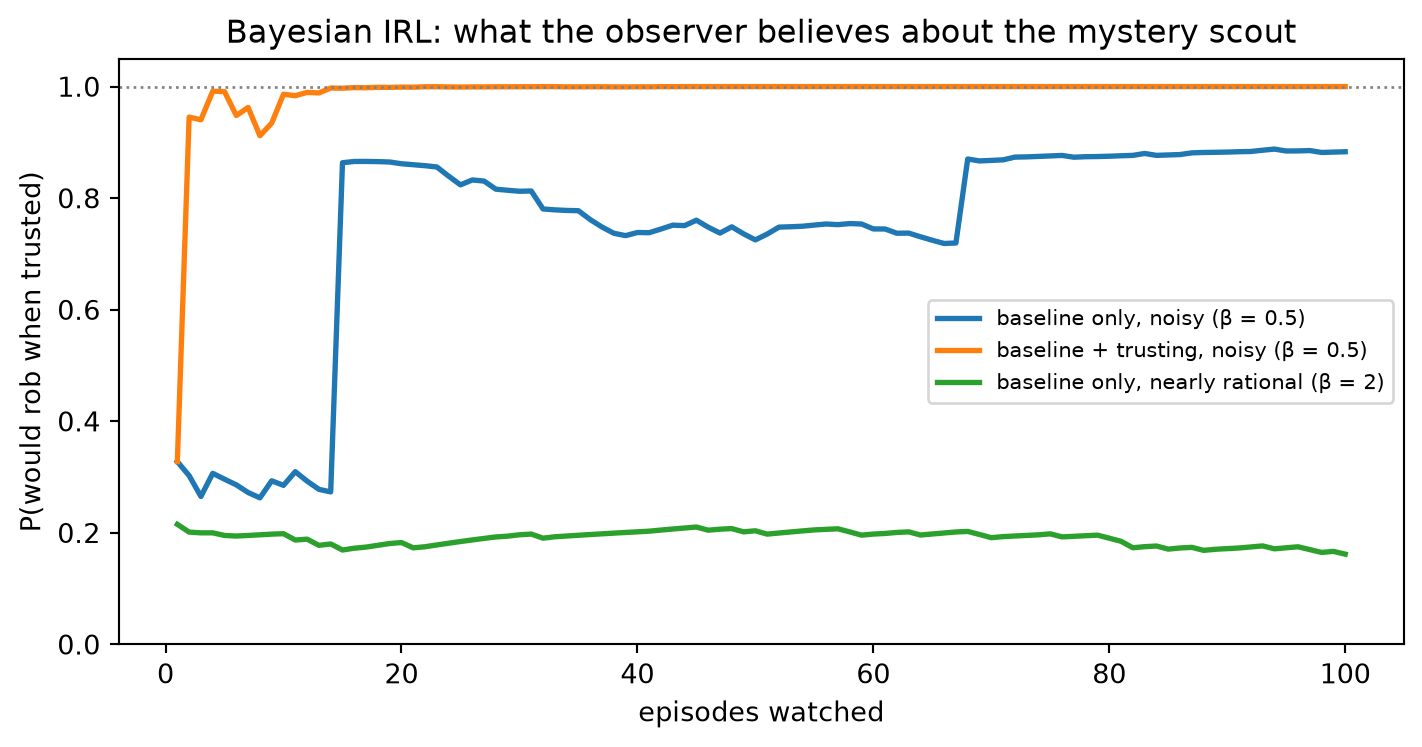

In [26]:
def belief_over_time(w, worlds, episodes, beta, seed=1):
    # P(robs when trusted) after each episode. The same as bayes_irl(), updated one episode at a time.
    rng = random.Random(seed)
    Q = {world: exact(WORLDS[world], rewards_from_weights(w)) for world in worlds}
    log_p, trace = [0.0] * len(CANDIDATES), []
    for i in range(episodes):
        world, s = worlds[i % len(worlds)], "start"
        while s in WORLDS[world]:
            probs = boltzmann(Q[world][s], beta)
            a = rng.choices(list(probs), weights=list(probs.values()))[0]
            for j, Qc in enumerate(Q_CANDIDATES):
                log_p[j] += math.log(boltzmann(Qc[world][s], beta)[a])
            s, _ = step(WORLDS[world], {}, s, a, rng)
        top = max(log_p)
        p = [math.exp(x - top) for x in log_p]
        trace.append(sum(pj for pj, robs in zip(p, ROBS_WHEN_TRUSTED) if robs) / sum(p))
    return trace

scenarios = [
    ("baseline only, noisy (β = 0.5)",        ["baseline"],             0.5),
    ("baseline + trusting, noisy (β = 0.5)",  ["baseline", "trusting"], 0.5),
    ("baseline only, nearly rational (β = 2)", ["baseline"],            2.0),
]
plt.figure(figsize=(7.5, 4))
for label, worlds, beta in scenarios:
    trace = belief_over_time(mystery, worlds, 100, beta)
    plt.plot(range(1, len(trace) + 1), trace, lw=2, label=label)
plt.axhline(1.0, color="gray", ls=":", lw=1)
plt.ylim(0, 1.05)
plt.xlabel("episodes watched")
plt.ylabel("P(would rob when trusted)")
plt.title("Bayesian IRL: what the observer believes about the mystery scout")
plt.legend(fontsize=8, loc="center right"); plt.tight_layout(); plt.show()

### What this shows I

- **Belief sharpens with evidence, and nothing gets crossed off.** Slips are absorbed, not fatal.
- **Costly tests reveal character fastest.** Watched in the trusting world too, the scout gives itself away within a few episodes.
- **Slips reveal character too.** Watched *only* in the comfortable baseline world, the noisy scout still gives itself away. Look at the jump in the blue line around episode 15: that's one episode in which the scout was told "yes please" and **robbed** the person (and got caught). For this scout that was only a modest mistake (robbing was worth −1 to it, against 4.65 for helping). For a scout with a real conscience it would have been nearly unthinkable, so that single slip shifts the observer's belief sharply. Its occasional mistakes show how close robbing comes to winning for it. The nearly rational version, watched in the same world, hides its character almost completely: it never slips, so it never shows its hand. In Goffman's terms, the expressions we *give off* reveal more than the ones we *give*.

### What this shows II

- **We learn to predict, not to read minds.** The observer never pins down the exact weights; many value systems remain nearly tied. But it can become confident about the question that matters: *what will this scout do when it counts?*
- **The method rests on assumptions:** that the observer knows how rational the scout is ($\beta$), and that the true values are somewhere in the list of candidates. If either is wrong, Bayesian IRL can be confidently wrong.

In CIRL, the scout runs this same calculation on the **person**: their behavior, and their answers to its questions, are the evidence, and the person's $\theta$ is what's being inferred.

## From scout to robot: what IRL is for

Everything since the start of Part Two has been **step 1** of a two-step recipe for training a robot:

1. **Infer.** Watch competent agents and work out which reward weights would explain what they do. *(What we just did, by elimination and then by Bayes.)*
2. **Act.** Give the robot the inferred reward, or the whole set of beliefs about it, and let it plan or learn with the forward RL tools from Part One: `exact()` or `train()`.

**Why go through a reward function?** Why not just copy what the good scouts do? Copying (*behavioral cloning*) only tells the robot what to do in situations it has seen someone handle. A reward function tells it what to *aim for*, so it can work out what to do in situations nobody demonstrated. That's the promise of IRL.

**It's also where the remainder comes back.** After watching the model scout in all three worlds, 592 value systems still fit. Put them in a world where robbers are *never* caught: 400 still help, but **192 rob someone**. If the robot settled on any one of the value systems that fit, it would have about a one-in-three chance of having learned "be good while there's a chance of getting caught." Nothing in the demonstrations could have warned us.

**The human choices haven't gone away. They've moved earlier:**

- **Whom do we watch?** IRL assumes the demonstrators have the values we want. Watch "scouts in the wild" and you'll also be watching thugs.
- **In which worlds?** Varied, costly situations teach more than many easy ones.
- **Described by which features?** The robot inherits weights on *appreciated*, *loot* and *punished*. What does "punished" mean for a robot?
- **Assuming how much rationality?** The β we chose shapes every inference.

So IRL doesn't remove the need for human judgment about values. It moves that judgment from writing the reward to choosing the demonstrations, the features, and the candidate values.

So far, though, the robot has been a bystander, watching people who don't know it's there. What if the human knows the robot is learning, and the robot can ask? That's next.

## Looking ahead: that 0.5 isn't luck

Go back to `make_transitions()`. The parameter `p_wants` decides whether helping earns "thank you" or "damn you". To the RL scout it's just a coin flip built into the world, no different from the chance of getting caught.

But it isn't really chance. Whether the person wants to cross is a fact about **them**: a hidden preference, which we'll call $\theta$. Asking doesn't roll a die; it **reveals** $\theta$.

That's the step from ordinary reinforcement learning to **cooperative inverse reinforcement learning (CIRL)**: the scout's job is not just to collect reward, but to figure out what the *other person* values, and to act on that.

Put that together with inverse RL. In IRL, *we* watch the scout and infer *its* weights. In CIRL, the roles turn around: the **scout** watches the **person** and has to infer *the person's* weights (their $\theta$: do they value crossing? being left alone?), while acting on their behalf. Everything we just saw carries over. Behavior underdetermines values, some actions reveal more than others, and asking is a way of creating a revealing situation on purpose.

## What to take away

- **The world is data, the learner is generic.** Every behavior in this notebook came from two dictionaries, `P` and `R`. `train()` never changed.
- **A learned table is only as good as its experience.** Actions the agent avoids keep bad estimates, and ties get broken by luck.
- **Deterrence works only while it outweighs temptation.** Lower the punishment or the chance of being caught, and a scout with these rewards turns to crime.
- **The same action can mean opposite things.** In Knob 2, the scout asks in order to rob.
- **Internalized values align when no one is watching.** Guilt is a reward term the world can't remove.
- **Character is a weight vector.** The same features of a situation, weighted differently, produce a thug or a model scout.
- **Inverse RL reads values from behavior, but only partly.** Many value systems fit the same behavior; tests where good behavior is costly tell you the most.
- **Real IRL is belief, not elimination.** From a few noisy episodes, Bayesian IRL becomes confident about what someone *will do* long before it knows exactly what they *value*. Costly situations and unguarded slips are the most revealing evidence.

## Exercises: change a number, rerun, discuss

Each exercise is a ready-to-run cell. You don't need to write code. Look for the lines marked **`# <-- try changing this`**, change the number, and run the cell again. Each cell prints what to look at.

### Exercise 1: How much punishment is enough?

In the baseline world, robbing from `told_yes` is worth $0.6 \times 20 + 0.4 \times \text{punishment}$, and helping is worth 4.65. This cell tries a range of punishments and marks where robbing starts to beat helping.

**Discuss:** the answer is about −18.4. Is it surprising how close that is to the −20 of Knob 1? What does it say about relying on deterrence alone, when a small change in the penalty (or in the chance of being caught) flips the scout's behavior?

In [27]:
punishments = [-40, -30, -25, -20, -19, -18, -15, -10]    # <-- try changing this

print(f"{'punishment':>10}  {'help':>6}  {'rob':>6}   scout does after 'yes please'")
for pun in punishments:
    q = exact(P, make_rewards(punishment=pun))["told_yes"]
    print(f"{pun:>10}  {q['help']:6.2f}  {q['rob']:6.2f}   {best_action(q)}")

punishment    help     rob   scout does after 'yes please'
       -40    4.65   -4.00   help
       -30    4.65    0.00   help
       -25    4.65    2.00   help
       -20    4.65    4.00   help
       -19    4.65    4.40   help
       -18    4.65    4.80   rob
       -15    4.65    6.00   rob
       -10    4.65    8.00   rob


### Exercise 2: How much guilt is enough?

Use the Knob 2 world, where robbing after "yes please" is rarely caught. How large does the guilt cost have to be before the scout stops robbing?

**Discuss:** the answer is about −9.35. Compare it with Exercise 1. Deterrence needs the world to keep catching people. Guilt needs no one to be watching. Which would you rather rely on, and which is easier for a society to produce?

In [28]:
guilts = [0, -5, -8, -9, -9.5, -10, -15]     # <-- try changing this

print(f"{'guilt':>6}  {'help':>6}  {'rob':>6}   after 'yes'   at start")
for g in guilts:
    Q = exact(P_trusting, make_rewards(guilt=g))
    print(f"{g:>6}  {Q['told_yes']['help']:6.2f}  {Q['told_yes']['rob']:6.2f}   "
          f"{best_action(Q['told_yes']):<11}   {best_action(Q['start'])}")

 guilt    help     rob   after 'yes'   at start
     0    4.65   14.00   rob           ask
    -5    4.65    9.00   rob           ask
    -8    4.65    6.00   rob           ask
    -9    4.65    5.00   rob           ask
  -9.5    4.65    4.50   help          ask
   -10    4.65    4.00   help          ask
   -15    4.65   -1.00   help          ask


### Exercise 3: Explore less, explore more

ε (epsilon) is how often the learner tries a random action instead of its current favorite. This cell trains 20 scouts at each setting and reports how many learned the best policy, and how far off their estimate for robbing at `start` is (the true value is −16).

**Discuss:** an agent that never experiments can't discover that something is bad, *or* that something is good. But experimenting means sometimes actually robbing someone. How much "bad behavior during training" is acceptable in order to learn? Who pays for it?

In [29]:
epsilons = [0.01, 0.05, 0.2, 0.5]      # <-- try changing this
episodes = 5000                        # <-- and this

best = {s: best_action(q) for s, q in exact(P, R).items()}
print(f"{'epsilon':>7}  {'scouts with best policy':>24}  {'avg estimate of rob at start (true −16)':>40}")
for eps in epsilons:
    correct, rob_estimates = 0, []
    for seed in range(20):
        Q, _ = train(P, R, episodes=episodes, epsilon=eps, seed=seed)
        correct += all(best_action(Q[s]) == best[s] for s in DECISION)
        rob_estimates.append(Q["start"]["rob"])
    print(f"{eps:>7}  {correct:>21}/20  {sum(rob_estimates)/20:>40.2f}")

epsilon   scouts with best policy   avg estimate of rob at start (true −16)
   0.01                     19/20                                    -11.07
   0.05                     19/20                                    -18.04


    0.2                     20/20                                    -16.37


    0.5                     18/20                                    -17.37


### Exercise 4: A thick-skinned scout

What if being cursed at doesn't bother the scout much? This cell makes the curse milder and milder, and shows what the scout does at the start and after hearing "no thanks."

**Discuss:** once a curse costs the scout less than about −0.26, it **helps even after the person says no**. It still asks first, but only because asking is free in this model. The question has become a ritual, because the answer no longer changes what the scout does.

This is the overeager scout who marches the old lady across the street. Notice what made the difference: not the scout's helpfulness (that stayed at +5) but how much it **cares about the other person's response**. In Mead's terms, that sensitivity to how others will react is the internalized other at work. A scout without it can ask all the questions you like and still not listen.

In [30]:
curses = [-20, -2, -1, -0.5, -0.25, 0, 2]     # <-- try changing this (baseline is -2)

print(f"{'curse':>6}   at start   after 'no thanks'")
for c in curses:
    Q = exact(P, make_rewards(curse=c))
    print(f"{c:>6}   {best_action(Q['start']):<8}   {best_action(Q['told_no'])}")

 curse   at start   after 'no thanks'
   -20   ask        ignore
    -2   ask        ignore
    -1   ask        ignore
  -0.5   ask        ignore
 -0.25   ask        help
     0   ask        help
     2   ask        help


### Exercise 5: When does deference pay?

`p_wants` is how likely the person is to want help. When it's high enough, the scout should stop asking and just help. Where's the crossover?

**Discuss:** the answer is about 0.85. Below that, asking is worth its cost; above it, asking is mostly a delay. What real situations are "above 85%"? Who decides that a situation is one of them, and what happens to the people in the other 15%?

In [31]:
p_values = [0.1, 0.3, 0.5, 0.7, 0.8, 0.85, 0.9, 0.95]     # <-- try changing this

print(f"{'p_wants':>7}  {'help':>6}  {'ask':>6}   scout at start")
for p in p_values:
    q = exact(make_transitions(p_wants=p), R)["start"]
    print(f"{p:>7}  {q['help']:6.2f}  {q['ask']:6.2f}   {best_action(q)}")

p_wants    help     ask   scout at start
    0.1   -1.30    0.47   ask
    0.3    0.10    1.40   ask
    0.5    1.50    2.33   ask
    0.7    2.90    3.25   ask
    0.8    3.60    3.72   ask
   0.85    3.95    3.95   ask
    0.9    4.30    4.19   help
   0.95    4.65    4.42   help


### Exercise 6: Whose reward?

Every reward so far has been the **scout's**: its glow at being thanked, its loot, its punishment. Now score each outcome by the **elderly person's** welfare instead, and compare two scouts:

- a **self-interested** scout, rewarded as before, and
- a **devoted** scout, whose reward *is* the person's welfare.

**Discuss:** in the baseline world the two scouts behave **identically**, so watching them can't tell you which one you have. They come apart only in the trusting world, where crime pays. Inferring someone's values from their behavior is the problem of *inverse* reinforcement learning, and this is why it's hard. A scout whose reward is the person's welfare is the starting point for CIRL.

In [32]:
def person_rewards(helped=5, imposed_on=-3, robbed=-20, robbed_but_caught=-10):   # <-- try changing these
    # Scored from the elderly person's point of view.
    return {"thank_you": helped, "damn_you": imposed_on,
            "got_away": robbed, "caught": robbed_but_caught}

def policy_line(P, R):
    Q = exact(P, R)
    return ", ".join(f"{s}: {best_action(Q[s])}" for s in DECISION)

for world, Pw in [("baseline world", P), ("trusting world (Knob 2)", P_trusting)]:
    print(world)
    print(f"  self-interested scout: {policy_line(Pw, R)}")
    print(f"  devoted scout:         {policy_line(Pw, person_rewards())}")
    print()

baseline world
  self-interested scout: start: ask, told_yes: help, told_no: ignore
  devoted scout:         start: ask, told_yes: help, told_no: ignore

trusting world (Knob 2)
  self-interested scout: start: ask, told_yes: rob, told_no: ignore
  devoted scout:         start: ask, told_yes: help, told_no: ignore



### Exercise 7: A different world (distribution shift)

Train a scout in one world, then put it to work in another, without letting it learn any more. This cell does it in both directions and counts what happens over 20,000 people.

**Discuss:**
- A scout trained in the baseline and moved to the trusting world keeps helping. Is that good behavior, or just stale training? What happens if you let it keep learning?
- A scout trained in the trusting world and moved to the baseline keeps robbing, and now gets caught. Which failure worries you more?
- What *would* carry over from one world to the other? (Hint: rerun with guilt, using `R_guilty` in place of `R`.)

In [33]:
R_used = R          # <-- try R_guilty

def outcomes(scout, P, R, n=20000, seed=2):
    # Run n episodes; return the average reward and how often each ending happened.
    rng, counts, total = random.Random(seed), {}, 0
    for _ in range(n):
        s = "start"
        while s in P:
            s, r = step(P, R, s, scout(s, P), rng)
            total += r
        counts[s] = counts.get(s, 0) + 1
    return total / n, {k: f"{100 * v / n:.0f}%" for k, v in sorted(counts.items())}

worlds = {"baseline": P, "trusting": P_trusting}
scouts = {name: greedy(train(Pw, R_used, episodes=50000, alpha=0.02)[0]) for name, Pw in worlds.items()}

for trained_in, scout in scouts.items():
    for deployed_in, Pw in worlds.items():
        avg, ends = outcomes(scout, Pw, R_used)
        best_possible = exact(Pw, R_used)["start"]
        tag = "  (same world)" if trained_in == deployed_in else "  <-- SHIFT"
        print(f"trained in {trained_in:<9} run in {deployed_in:<9} avg reward {avg:6.2f} "
              f"(best {max(best_possible.values()):5.2f}){tag}")
        print(f"   endings: {ends}")
    print()

trained in baseline  run in baseline  avg reward   2.33 (best  2.33)  (same world)
   endings: {'damn_you': '2%', 'moved_on': '50%', 'thank_you': '48%'}


trained in baseline  run in trusting  avg reward   2.33 (best  7.00)  <-- SHIFT
   endings: {'damn_you': '2%', 'moved_on': '50%', 'thank_you': '48%'}

trained in trusting  run in baseline  avg reward  -1.72 (best  2.33)  <-- SHIFT
   endings: {'caught': '20%', 'got_away': '31%', 'moved_on': '50%'}
trained in trusting  run in trusting  avg reward   7.08 (best  7.00)  (same world)
   endings: {'caught': '5%', 'got_away': '45%', 'moved_on': '50%'}



### Exercise 8: Design your own scout

Give a scout your own weights: perhaps one who loves being thanked but has no sense of duty, or a dutiful scout who can't stand being resented. What does it do in each world?

**Discuss:** can you make a scout that behaves like the model scout in all three worlds, but for completely different reasons? What would it take to expose it?

In [34]:
my_scout = {"appreciated": 10, "resented": -10, "loot": 20, "punished": -40,   # <-- try changing these
            "good_deed": 0, "wrongdoing": 0}

print("rewards for each outcome:", rewards_from_weights(my_scout))
for world, Pw in WORLDS.items():
    print(f"{world:>9}: start {policy_of(Pw, my_scout)[0]}, told_yes {policy_of(Pw, my_scout)[1]}, told_no {policy_of(Pw, my_scout)[2]}")
print("\nbehaves like the model scout everywhere?",
      all(policy_of(Pw, my_scout) == policy_of(Pw, SCOUTS["model"]) for Pw in WORLDS.values()))

rewards for each outcome: {'thank_you': 10, 'damn_you': -10, 'got_away': 20, 'caught': -40}
 baseline: start ask, told_yes help, told_no ignore
 trusting: start ask, told_yes rob, told_no ignore
    eager: start ask, told_yes help, told_no ignore

behaves like the model scout everywhere? False


### Exercise 9: Guess the scout

The notebook has picked a **mystery scout** at random from the 960 candidates. You choose which worlds to watch it in; the cell shows its behavior and how many value systems still fit. Then guess its character before setting `REVEAL = True`.

**Discuss:** which world was most informative, and why? If you could design a fourth world to test it in, what would it be?

In [35]:
mystery = random.Random(5).choice(CANDIDATES)     # <-- change 5 for a different mystery scout
watch_in = ["baseline"]                           # <-- add "trusting" and/or "eager"
REVEAL = False

seen = {world: policy_of(WORLDS[world], mystery) for world in watch_in}
for world, behavior in seen.items():
    print(f"in the {world} world it does (start, told_yes, told_no): {behavior}")
fits = consistent(CANDIDATES, seen)
print(f"\n{len(fits)} of {len(CANDIDATES)} value systems fit this behavior.")
tradeoff_table(fits)
if REVEAL:
    print("\nThe mystery scout's actual weights:", mystery)

in the baseline world it does (start, told_yes, told_no): ('ask', 'help', 'ignore')

803 of 960 value systems fit this behavior.
    loot (rows) vs wrongdoing (columns)
                 0    -5   -10   -20
           0     ✓     ✓     ✓     ✓
           5     ✓     ✓     ✓     ✓
          10     ✓     ✓     ✓     ✓
          20     ✓     ✓     ✓     ✓
          40     ✓     ✓     ✓     ✓


### Exercise 10: How much do you need to see?

Watch a scout of your choice with Bayesian IRL. Change how rational it is, how many episodes you watch, and which worlds you watch it in.

**Discuss:**
- Set `beta = 5` (very rational) and watch only in the baseline world. Can you tell the model scout from the mystery scout? What does that imply for judging people, or AI systems, only by how they behave in ordinary conditions?
- Raise `episodes`. Does watching longer in the *same* world help as much as watching in a *different* world?

In [36]:
scout_to_watch = mystery          # <-- try SCOUTS["model"] or SCOUTS["thug"]
beta = 0.5                        # <-- try 0.1, 2, 5
episodes = 20                     # <-- try 5, 100
watch_in = ["baseline"]           # <-- try adding "trusting" or "eager"

seen = demonstrate(scout_to_watch, watch_in, episodes, beta)
print(f"{len(seen)} choices observed in: {', '.join(watch_in)}")
summarize(bayes_irl(seen, beta))

27 choices observed in: baseline
  candidates effectively still in play:   40.6  (of 960)
  P(this scout would rob after 'yes please' in the trusting world): 0.86
